In [1]:
import os
import re
import math
import numpy as np
import pandas as pd
import geopandas as gpd

from shapely.geometry import Point
from shapely.ops import linemerge
from osgeo import gdal
from exactextract import exact_extract

In [2]:
gps_path = "../../intermediate/active_move_respond_CH.geojson"
ndvi_dir = "../../raw/ndvi_year59_cloud30_topo"

In [ ]:
gdf = gpd.read_file(gps_path, driver='GeoJSON')


gdf["timeStart"] = pd.to_datetime(gdf["timeStart"])
gdf["year"] = gdf["timeStart"].dt.year
gdf["month"] = gdf["timeStart"].dt.month
gdf["month_key"] = gdf["timeStart"].dt.strftime("%Y_%m")

gdf['duration_s'] = (gdf['timeEnd'] - gdf['timeStart']).dt.total_seconds()

In [ ]:
gdf

In [5]:
# =========================================
# 1) geometry helper
# =========================================
def to_single_line(geom):
    if geom is None or geom.is_empty:
        return None

    if geom.geom_type == "LineString":
        return geom

    if geom.geom_type == "MultiLineString":
        merged = linemerge(geom)
        if merged.geom_type == "LineString":
            return merged
        if merged.geom_type == "MultiLineString":
            geoms = list(merged.geoms)
            if len(geoms) == 0:
                return None
            return max(geoms, key=lambda g: g.length)
        return None

    if geom.geom_type == "Point":
        return geom

    return None

In [6]:
# =========================================
# 2) sample every 10 m
# =========================================
def sample_every_n_meters(geom, step_m=10, include_last=True):
    geom = to_single_line(geom)

    if geom is None or geom.is_empty:
        return [], 0, 0

    if geom.geom_type == "Point":
        return [geom], 1, 1

    coords = list(geom.coords)
    n_fix_original = len(coords)

    if n_fix_original == 0:
        return [], 0, 0

    line_length = geom.length
    if line_length == 0:
        return [Point(coords[0])], n_fix_original, 1

    distances = list(np.arange(0, line_length, step_m))
    if include_last and (len(distances) == 0 or distances[-1] < line_length):
        distances.append(line_length)

    pts = [geom.interpolate(float(d)) for d in distances]
    return pts, n_fix_original, len(pts)

In [7]:
# =========================================
# 3) year -> tif parts
# =========================================
def build_year_tifs(ndvi_dir, years=(2024, 2025), year_pattern=r"(20\d{2})"):
    year_tifs = {}
    for year in years:
        year_tifs[year] = []

    for fn in os.listdir(ndvi_dir):
        if fn.lower().endswith(".tif"):
            m = re.search(year_pattern, fn)
            if m:
                y = int(m.group(1))
                if y in year_tifs:
                    year_tifs[y].append(os.path.join(ndvi_dir, fn))

    for y in year_tifs:
        year_tifs[y] = sorted(year_tifs[y])

    return year_tifs

In [8]:
# =========================================
# 4) build one VRT per year
#    this is much lighter than merging all tiles to one in-memory raster
# =========================================
def build_year_vrt(year, tif_list, vrt_dir):
    os.makedirs(vrt_dir, exist_ok=True)
    vrt_path = os.path.join(vrt_dir, f"ndvi_year_{year}.vrt")

    if os.path.exists(vrt_path):
        return vrt_path

    vrt = gdal.BuildVRT(vrt_path, tif_list)
    if vrt is None:
        raise RuntimeError(f"Failed to build VRT for year {year}")
    vrt = None  # flush

    return vrt_path

In [9]:
# =========================================
# 5) expand one chunk of trip legs to sampled points
# =========================================
def expand_trip_samples_chunk(
    gdf_chunk,
    id_cols=("pid", "tripleg_id"),
    step_m=10,
    include_last=True,
    duration_col=None,
    distance_col=None,
):
    rows = []

    gdf_chunk = gdf_chunk.reset_index(drop=False).rename(columns={"index": "_trip_idx"})

    keep_cols = ["_trip_idx", "year"]
    keep_cols += [c for c in id_cols if c in gdf_chunk.columns]

    for c in [duration_col, distance_col]:
        if c is not None and c in gdf_chunk.columns:
            keep_cols.append(c)

    keep_cols = list(dict.fromkeys(keep_cols))

    for _, row in gdf_chunk.iterrows():
        pts, n_fix_original, n_fix_sampled = sample_every_n_meters(
            row.geometry,
            step_m=step_m,
            include_last=include_last,
        )

        for j, pt in enumerate(pts):
            out = {c: row[c] for c in keep_cols}
            out["n_fix_original"] = n_fix_original
            out["n_fix_sampled"] = n_fix_sampled
            out["sample_idx"] = j
            out["geometry"] = pt
            rows.append(out)

    if not rows:
        return gpd.GeoDataFrame(columns=keep_cols + ["n_fix_original", "n_fix_sampled", "sample_idx", "geometry"],
                                geometry="geometry", crs=gdf_chunk.crs)

    return gpd.GeoDataFrame(rows, geometry="geometry", crs=gdf_chunk.crs)

In [10]:
# =========================================
# 6) exactextract on one sampled-point chunk
# =========================================
def extract_qi_exactextract_chunk(
    pts_chunk,
    vrt_path,
    buffer_m=50,
    id_cols=("pid", "tripleg_id"),
    strategy="raster-sequential",
    max_cells_in_memory=3_000_000,
):
    pts_chunk = pts_chunk.copy()

    # build 50m circular buffers
    buf = pts_chunk.copy()
    buf["geometry"] = buf.geometry.buffer(buffer_m)

    include_cols = ["_trip_idx", "year", "n_fix_original", "n_fix_sampled", "sample_idx"]
    include_cols += [c for c in id_cols if c in buf.columns]
    include_cols = list(dict.fromkeys(include_cols))

    res = exact_extract(
        vrt_path,                     # pass VRT path directly
        buf,                          # GeoDataFrame
        ["mean"],
        include_cols=include_cols,
        output="pandas",
        strategy=strategy,
        max_cells_in_memory=max_cells_in_memory,
    )

    pts_chunk["qi"] = res["mean"].to_numpy()
    return pts_chunk

In [11]:
# =========================================
# 7) aggregate sampled points back to trip legs
# =========================================
def aggregate_trip_chunk(
    pts_chunk,
    gdf_chunk,
    id_cols=("pid", "tripleg_id"),
    duration_col=None,
    distance_col=None,
):
    pts_chunk = pts_chunk[pts_chunk["qi"].notna()].copy()
    if len(pts_chunk) == 0:
        return pd.DataFrame()

    grp_cols = ["_trip_idx", "year"] + [c for c in id_cols if c in pts_chunk.columns]
    grp_cols = list(dict.fromkeys(grp_cols))

    trip_agg = (
        pts_chunk.groupby(grp_cols, as_index=False)
        .agg(
            n_fix_original=("n_fix_original", "first"),
            n_fix_sampled=("n_fix_sampled", "first"),
            mean_qi=("qi", "mean"),
            median_qi=("qi", "median"),
            sd_qi=("qi", "std"),
        )
    )

    gdf_chunk2 = gdf_chunk.reset_index(drop=False).rename(columns={"index": "_trip_idx"})
    merge_cols = ["_trip_idx"]

    if duration_col is not None and duration_col in gdf_chunk2.columns:
        merge_cols.append(duration_col)

    if distance_col is not None and distance_col in gdf_chunk2.columns:
        merge_cols.append(distance_col)
    else:
        gdf_chunk2["trip_distance_m_geom"] = gdf_chunk2.geometry.length
        merge_cols.append("trip_distance_m_geom")

    trip_agg = trip_agg.merge(gdf_chunk2[merge_cols], on="_trip_idx", how="left")

    trip_agg["TGSE_est"] = trip_agg["mean_qi"] * trip_agg["n_fix_original"]

    if duration_col is not None and duration_col in trip_agg.columns:
        trip_agg["UTGSE_est"] = trip_agg["TGSE_est"] / trip_agg[duration_col]
        trip_agg["UTGSE_est_per_min"] = trip_agg["TGSE_est"] / (trip_agg[duration_col] / 60)
        trip_agg.loc[trip_agg[duration_col] <= 0, ["UTGSE_est", "UTGSE_est_per_min"]] = np.nan
    else:
        trip_agg["UTGSE_est"] = np.nan
        trip_agg["UTGSE_est_per_min"] = np.nan

    if distance_col is not None and distance_col in trip_agg.columns:
        trip_agg["UDGSE_est"] = trip_agg["TGSE_est"] / trip_agg[distance_col]
        trip_agg.loc[trip_agg[distance_col] <= 0, "UDGSE_est"] = np.nan
    else:
        trip_agg["UDGSE_est"] = trip_agg["TGSE_est"] / trip_agg["trip_distance_m_geom"]
        trip_agg.loc[trip_agg["trip_distance_m_geom"] <= 0, "UDGSE_est"] = np.nan

    return trip_agg

In [12]:
# =========================================
# 8) main function: yearly, chunked, VRT-backed
# =========================================
def compute_tripleg_ndvi_exposure_yearly_exactextract_fast(
    gdf,
    ndvi_dir,
    vrt_dir,
    buffer_m,
    years=(2024, 2025),
    id_cols=("pid", "tripleg_id"),
    step_m=10,
    include_last=True,
    duration_col=None,
    distance_col=None,
    chunk_n_triplegs=1000,
    strategy="raster-sequential",
    max_cells_in_memory=3_000_000,
    return_sampled_points=False,
):
    if gdf.crs is None:
        raise ValueError("gdf.crs 不能为空")
    if "year" not in gdf.columns:
        raise ValueError("gdf 必须包含 year 列")

    # keep meter-based CRS for 10m sampling and 50m buffer
    if str(gdf.crs).upper() != "EPSG:2056":
        gdf = gdf.to_crs("EPSG:2056").copy()
    else:
        gdf = gdf.copy()

    year_tifs = build_year_tifs(ndvi_dir, years=years)

    # build VRTs once
    year_vrts = {}
    for year in years:
        tif_list = year_tifs.get(year, [])
        if len(tif_list) == 0:
            print(f"Year {year}: no tif parts found")
            continue
        year_vrts[year] = build_year_vrt(year, tif_list, vrt_dir)

    trip_results = []
    sampled_results = []

    for year, g_year in gdf.groupby("year"):
        year = int(year)
        if year not in year_vrts:
            print(f"Skip year {year}: no VRT available")
            continue

        vrt_path = year_vrts[year]
        n = len(g_year)
        n_chunks = math.ceil(n / chunk_n_triplegs)

        print(f"Year {year}: {n} trip legs, {n_chunks} chunk(s), VRT={os.path.basename(vrt_path)}")

        g_year = g_year.reset_index(drop=True)

        for i in range(n_chunks):
            start = i * chunk_n_triplegs
            end = min((i + 1) * chunk_n_triplegs, n)
            g_chunk = g_year.iloc[start:end].copy()

            pts_chunk = expand_trip_samples_chunk(
                gdf_chunk=g_chunk,
                id_cols=id_cols,
                step_m=step_m,
                include_last=include_last,
                duration_col=duration_col,
                distance_col=distance_col,
            )

            if len(pts_chunk) == 0:
                continue

            pts_chunk = extract_qi_exactextract_chunk(
                pts_chunk=pts_chunk,
                vrt_path=vrt_path,
                buffer_m=buffer_m,
                id_cols=id_cols,
                strategy=strategy,
                max_cells_in_memory=max_cells_in_memory,
            )

            trip_chunk = aggregate_trip_chunk(
                pts_chunk=pts_chunk,
                gdf_chunk=g_chunk,
                id_cols=id_cols,
                duration_col=duration_col,
                distance_col=distance_col,
            )

            if len(trip_chunk) > 0:
                trip_results.append(trip_chunk)

            if return_sampled_points:
                sampled_results.append(pts_chunk)

            print(f"  chunk {i+1}/{n_chunks}: triplegs={len(g_chunk)}, sampled_pts={len(pts_chunk)}")

    trip_exposure = pd.concat(trip_results, ignore_index=True) if trip_results else pd.DataFrame()

    if return_sampled_points and sampled_results:
        sampled_pts = pd.concat(sampled_results, ignore_index=True)
    elif return_sampled_points:
        sampled_pts = gpd.GeoDataFrame(columns=["geometry"], geometry="geometry", crs=gdf.crs)
    else:
        sampled_pts = None

    return trip_exposure, sampled_pts

In [ ]:
trip_exposure, sampled_pts = compute_tripleg_ndvi_exposure_yearly_exactextract_fast(
    gdf=gdf,
    ndvi_dir=ndvi_dir,
    vrt_dir='../../raw/ndvi',
    years=(2024, 2025),
    id_cols=("PID", "trip_id"),
    step_m=10,
    include_last=True,
    buffer_m=200,
    duration_col="duration_s",
    distance_col="distance_m",
    chunk_n_triplegs=500,          
    strategy="raster-sequential",   
    max_cells_in_memory=3_000_000,
    return_sampled_points=False    
)


In [ ]:
gdf.head(5)

In [ ]:
trip_exposure

In [16]:
sampled_pts

In [17]:
trip_exposure.to_csv("../../intermediate/tripleg_ndvi_exposure_step10m_b200.csv", index=False)

<Axes: >

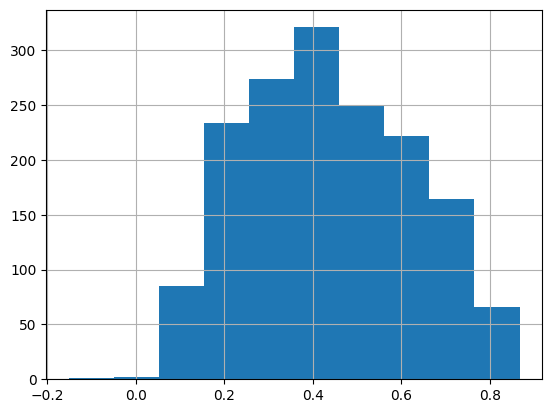

In [18]:
trip_exposure['mean_qi'].hist()

Episode-level distribution
N: 1620
Mean: 0.44685321270748135
Median: 0.4442321526696297
Mean - median: 0.0026210600378516746
Skewness: 0.12033967933487268


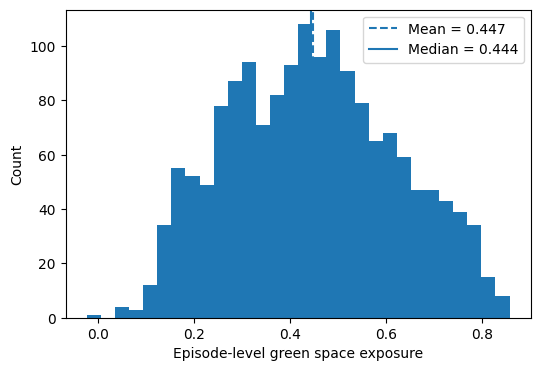

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew

# episode-level green space exposure
x = trip_exposure['mean_qi'].dropna()

# overall distribution
print("Episode-level distribution")
print("N:", len(x))
print("Mean:", x.mean())
print("Median:", x.median())
print("Mean - median:", x.mean() - x.median())
print("Skewness:", skew(x))

plt.figure(figsize=(6,4))
plt.hist(x, bins=30)
plt.axvline(x.mean(), linestyle='--', label=f"Mean = {x.mean():.3f}")
plt.axvline(x.median(), linestyle='-', label=f"Median = {x.median():.3f}")
plt.xlabel("Episode-level green space exposure")
plt.ylabel("Count")
plt.legend()
plt.show()

In [ ]:
person_gse = (
    trip_exposure
    .dropna(subset=['mean_qi'])
    .groupby('PID')
    .agg(
        gse_mean=('mean_qi', 'mean'),
        gse_median=('mean_qi', 'median'),
        n_episodes=('mean_qi', 'size')
    )
    .reset_index()
)

person_gse['mean_median_diff'] = person_gse['gse_mean'] - person_gse['gse_median']

print(person_gse[['gse_mean', 'gse_median', 'mean_median_diff', 'n_episodes']].describe())

plt.figure(figsize=(6,4))
plt.hist(person_gse['mean_median_diff'].dropna(), bins=30)
plt.axvline(0, linestyle='--')
plt.xlabel("Participant-level mean - median GSE")
plt.ylabel("Number of participants")
plt.show()

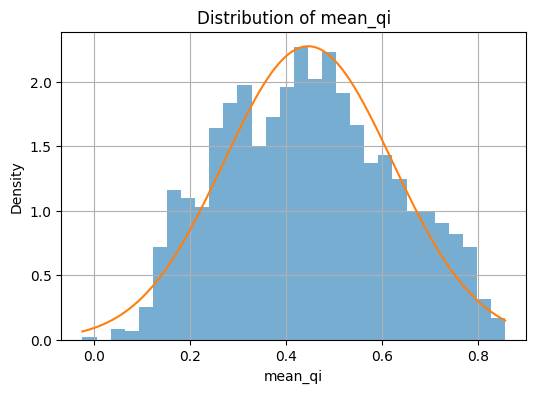

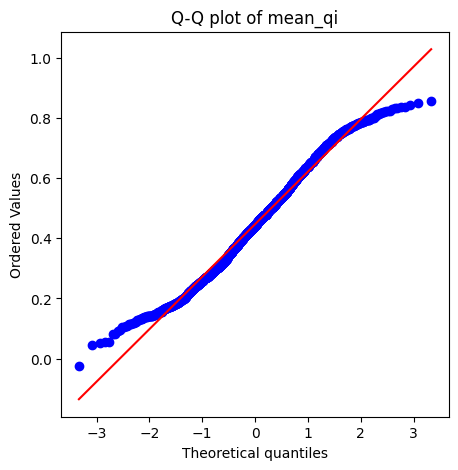

N: 1620
Mean: 0.44685321270748135
Median: 0.4442321526696297
SD: 0.1754609267580774
Skewness: 0.12033967933487268
Excess kurtosis: -0.7444152981998502
Shapiro-Wilk: ShapiroResult(statistic=np.float64(0.9860413873703927), pvalue=np.float64(2.0622000911447663e-11))
D'Agostino K^2: NormaltestResult(statistic=np.float64(106.8698016546995), pvalue=np.float64(6.216091944283448e-24))


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import skew, kurtosis, shapiro, normaltest

x = trip_exposure['mean_qi'].dropna()

# 1. Histogram + density
plt.figure(figsize=(6, 4))
x.hist(bins=30, density=True, alpha=0.6)
xmin, xmax = x.min(), x.max()
xs = np.linspace(xmin, xmax, 200)
plt.plot(xs, stats.norm.pdf(xs, x.mean(), x.std()))
plt.title("Distribution of mean_qi")
plt.xlabel("mean_qi")
plt.ylabel("Density")
plt.show()

# 2. Q-Q plot
plt.figure(figsize=(5, 5))
stats.probplot(x, dist="norm", plot=plt)
plt.title("Q-Q plot of mean_qi")
plt.show()

# 3. Numerical summaries
print("N:", len(x))
print("Mean:", x.mean())
print("Median:", x.median())
print("SD:", x.std())
print("Skewness:", skew(x))
print("Excess kurtosis:", kurtosis(x))  # normal distribution = 0

# 4. Normality tests
print("Shapiro-Wilk:", shapiro(x.sample(min(len(x), 5000), random_state=1)))
print("D'Agostino K^2:", normaltest(x))

In [ ]:
trip_exposure['UTGSE_est'].hist()